# Leaning-book controller: what the robot sees, and what it does

This notebook runs one episode of the **leaning** scenario with the scripted controller
(`scripted_controller.py`) and shows:

1. **What the robot's sensors would see**: the wrist camera, the fixed scene camera, and the wrist force/torque sensor.
2. **What the controller actually uses**: the book poses read straight from the simulator (privileged state),
   drawn as a cross-section of the target row with the planned contact point.
3. **The episode**: the leaning book's tilt, the slot width and the wrist force over time, plus a video from both cameras.
4. **A small batch evaluation** over several seeds.

The logic lives in the `.py` files; this notebook only imports and calls it.

**Run it** from the project folder:

```bash
uv run --with jupyter --with matplotlib --with mediapy jupyter lab explore_leaning.ipynb
```

(`mediapy` is only for the videos; without it the notebook falls back to a matplotlib animation.)

In [1]:
import math, time
import numpy as np
import mujoco
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from shelf_scene import ShelfConfig, book_tilt_deg
from scripted_controller import (ScriptedLeaningController, ShelfFrame, book_corners,
                                 make_leaning_episode, run_episode, DEFAULT_PANDA)

try:
    import mediapy
except ImportError:
    mediapy = None
    from matplotlib import animation
    from IPython.display import HTML

print("MuJoCo", mujoco.__version__, "| mediapy:", "yes" if mediapy else "no (matplotlib fallback)")

MuJoCo 3.15.0 | mediapy: yes


## Settings

Change `SEED` to see a different bookcase and leaning book. `TOOL_LENGTH` is the pusher rod on the hand (0 = bare fingers).

In [2]:
SEED = 0
TOOL_LENGTH = 0.08          # m
IMG_W, IMG_H = 480, 360     # camera image size
FPS = 15                    # video frame rate

## 1. Build a settled leaning episode

`make_leaning_episode` samples a bookcase, builds the MuJoCo scene with the rod on the hand, and lets physics settle
the row, so the leaning book rests in a real pose found by the simulator.

In [3]:
rng = np.random.default_rng(SEED)
model, data, row = make_leaning_episode(ShelfConfig(), rng, DEFAULT_PANDA, TOOL_LENGTH)
frame = ShelfFrame(row)

ti = row.target_index
print(f"{len(row.level_heights)} levels, target level {row.target_level}, board top {row.target_board_top:.2f} m")
print(f"{len(row.books)} books in the target row; the new book goes between "
      f"{row.books[ti-1].name} and {row.books[ti].name}")
print(f"new book: {1000*row.target_book.thickness:.0f} mm thick, {1000*row.target_book.height:.0f} mm tall")
print()
for i, b in enumerate(row.books):
    tilt = book_tilt_deg(data.xquat[model.body(b.name).id])
    mark = "  <- leaning" if tilt > 5 else ""
    slot = "   [slot]" if i == ti else ""
    print(f"{slot:9s}{b.name:8s} {1000*b.thickness:4.0f} mm thick, tilt {tilt:4.1f} deg{mark}")

3 levels, target level 2, board top 0.76 m
15 books in the target row; the new book goes between book_4 and book_5
new book: 48 mm thick, 292 mm tall

         book_0     54 mm thick, tilt  0.0 deg
         book_1     32 mm thick, tilt  0.0 deg
         book_2     39 mm thick, tilt  0.0 deg
         book_3     30 mm thick, tilt  0.0 deg
         book_4     54 mm thick, tilt 22.6 deg  <- leaning
   [slot]book_5     24 mm thick, tilt  0.0 deg
         book_6     43 mm thick, tilt  0.0 deg
         book_7     36 mm thick, tilt  0.0 deg
         book_8     20 mm thick, tilt  0.0 deg
         book_9     59 mm thick, tilt  0.0 deg
         book_10    35 mm thick, tilt  0.0 deg
         book_11    38 mm thick, tilt  0.0 deg
         book_12    27 mm thick, tilt  0.0 deg
         book_13    40 mm thick, tilt  0.0 deg
         book_14    53 mm thick, tilt  0.0 deg


## 2. What the robot's sensors would see

The scene has three sensors on or around the robot:

- `panda/wrist_cam`: a camera on the hand (RealSense D405-like), looking along the fingers.
- `scene_cam`: a fixed camera in front of the shelf, off to one side, aimed at the target row.
- `panda/ft_force`, `panda/ft_torque`: a 6-axis force/torque sensor at the wrist flange.

**The scripted controller uses none of them yet.** These are the inputs a perception module (or the residual
policy) would work from.

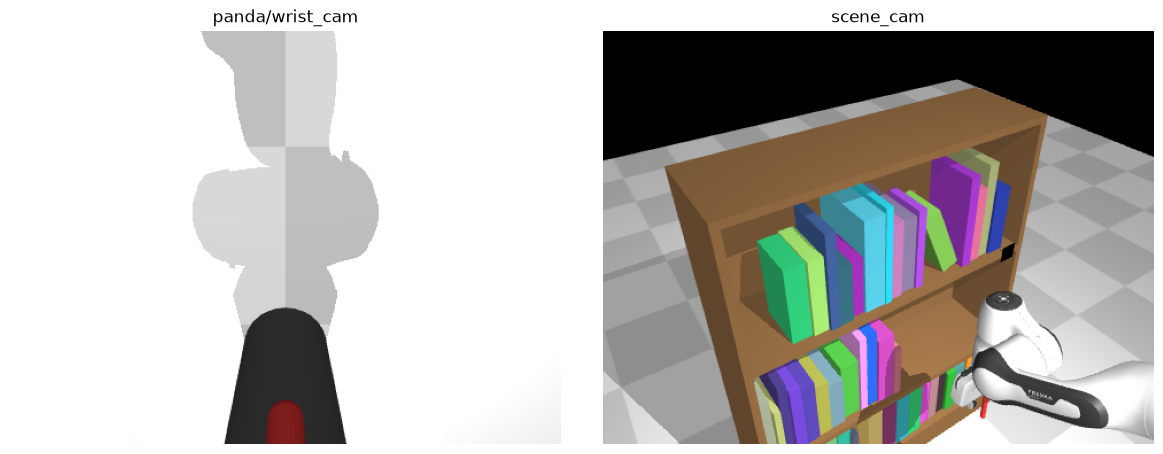

wrist force  [N]   [-0.07  0.   -7.46]
wrist torque [N m] [-0.    -0.074 -0.   ]
(At rest the sensor reads the weight of the hand and rod.)


In [4]:
renderer = mujoco.Renderer(model, height=IMG_H, width=IMG_W)

def find_name(objtype, suffix):
    # full name of the camera/sensor ending with `suffix` (the Panda's are prefixed "panda/")
    n = {mujoco.mjtObj.mjOBJ_CAMERA: model.ncam, mujoco.mjtObj.mjOBJ_SENSOR: model.nsensor}[objtype]
    names = [mujoco.mj_id2name(model, objtype, i) for i in range(n)]
    return next(x for x in names if x and x.endswith(suffix))

WRIST_CAM = find_name(mujoco.mjtObj.mjOBJ_CAMERA, "wrist_cam")
FT_FORCE = find_name(mujoco.mjtObj.mjOBJ_SENSOR, "ft_force")
FT_TORQUE = find_name(mujoco.mjtObj.mjOBJ_SENSOR, "ft_torque")

def render(cam):
    renderer.update_scene(data, camera=cam)
    return renderer.render().copy()

def wrench():
    f = data.sensor(FT_FORCE).data.copy()
    t = data.sensor(FT_TORQUE).data.copy()
    return f, t

mujoco.mj_forward(model, data)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, cam in zip(ax, (WRIST_CAM, "scene_cam")):
    a.imshow(render(cam)); a.set_title(cam); a.axis("off")
plt.tight_layout(); plt.show()

f, t = wrench()
print("wrist force  [N]  ", np.round(f, 2))
print("wrist torque [N m]", np.round(t, 3))
print("(At rest the sensor reads the weight of the hand and rod.)")

## 3. What the controller actually uses: privileged state

The controller reads each book's exact pose from `MjData` and works in the **shelf frame**
(x along the row, y out of the shelf, z up). Below is a cross-section of the target row seen from the front:

- red: the leaning book, blue: the book it rests on, grey: the rest
- the green dot is where the controller plans to put the rod (the highest point of the wedge it fits into)
- the dashed line is the backstop: the rod never pushes past it

In [ ]:
FRONT_FACE = [2, 6, 7, 3]   # book_corners() indices of the front face, in polygon order

def draw_row(ax, plan=None, tcp=None, title=""):
    z0 = row.target_board_top
    xs = []
    for b in row.books:
        C = book_corners(model, data, b.name, frame)[FRONT_FACE]
        colour = ("tab:red" if plan and b.name == plan.leaner else
                  "tab:blue" if plan and b.name in (row.books[ti-1].name, row.books[ti].name) else "0.75")
        ax.add_patch(Polygon(C[:, [0, 2]], closed=True, fc=colour, ec="k", lw=0.6, alpha=0.85))
        xs += list(C[:, 0])
    ax.axhline(z0, color="saddlebrown", lw=3)                                  # the board
    ax.axhline(z0 + row.clear_height, color="saddlebrown", lw=3, alpha=0.5)    # board above
    if plan is not None:
        ax.plot(plan.x_entry, plan.z, "o", color="limegreen", ms=9, mec="k", label="planned contact")
        ax.axvline(plan.x_limit, color="k", ls="--", lw=1, label="push backstop")
    if tcp is not None:
        ax.plot(tcp[0], tcp[2], "x", color="k", ms=10, mew=2, label="rod tip")
    lx = row.books[ti-1].x; rx = row.books[ti].x
    ax.set_xlim(min(lx, rx) - 0.18, max(lx, rx) + 0.18)
    ax.set_ylim(z0 - 0.02, z0 + row.clear_height + 0.02)
    ax.set_aspect("equal"); ax.set_xlabel("x along the row [m]"); ax.set_ylabel("z [m]")
    ax.set_title(title)
    if plan is not None:
        ax.legend(loc="upper right", fontsize=8)

ctl = ScriptedLeaningController(model, data, row, TOOL_LENGTH)
plan = ctl.plan
print(f"leaner: {plan.leaner}, top leans toward {'+x' if plan.lean_dir > 0 else '-x'}")
print(f"contact {1000*(plan.z - row.target_board_top):.0f} mm above the board, "
      f"wedge {1000*plan.wedge_at_z:.0f} mm wide there")
print(f"slot now {1000*ctl.slot_width(data):.1f} mm, new book needs {1000*row.target_book.thickness:.1f} mm")

fig, ax = plt.subplots(figsize=(9, 4.5))
draw_row(ax, plan, title=f"seed {SEED}: target row before the push")
plt.show()

## 4. Run the episode

Each physics step: the controller writes joint targets, MuJoCo steps. We log the phase, the leaning book's tilt,
the slot width, the rod tip and the wrist force, and grab frames from both cameras for the video.

In [ ]:
log = {k: [] for k in ("t", "phase", "tilt", "slot", "force", "tcp")}
frames_wrist, frames_scene = [], []
pos0 = {b.name: data.xpos[model.body(b.name).id].copy() for b in row.books}
tilt0 = {b.name: book_tilt_deg(data.xquat[model.body(b.name).id]) for b in row.books}

t0, t_done, every = data.time, None, max(1, int(round(1 / (FPS * model.opt.timestep))))
step, wall = 0, time.time()
while data.time - t0 < 25.0:
    ctl.step(data)
    mujoco.mj_step(model, data)
    if step % 25 == 0:                                       # log at 20 Hz
        f, _ = wrench()
        log["t"].append(data.time - t0); log["phase"].append(ctl.phase)
        log["tilt"].append(ctl.leaner_tilt(data)); log["slot"].append(1000 * ctl.slot_width(data))
        log["force"].append(np.linalg.norm(f)); log["tcp"].append(ctl.tcp_shelf(data))
    if step % every == 0:
        frames_wrist.append(render(WRIST_CAM)); frames_scene.append(render("scene_cam"))
    if ctl.phase == "done":
        t_done = t_done or data.time + 1.0
        if data.time > t_done:
            break
    step += 1

for k in log:
    log[k] = np.array(log[k])
print(f"simulated {data.time - t0:.1f} s in {time.time() - wall:.1f} s wall time, final phase: {ctl.phase}")

### Result

Same success test as `scripted_controller.py`: finished, slot at least the new book's thickness + 4 mm,
leaning book within 8° of upright, and no other book's tilt changed by 10° or more.

In [ ]:
gap = ctl.slot_width(data); need = row.target_book.thickness
tilt_after = ctl.leaner_tilt(data)
others = [b.name for b in row.books if b.name != plan.leaner]
dtilt = max(abs(book_tilt_deg(data.xquat[model.body(n).id]) - tilt0[n]) for n in others)
moved = max(np.linalg.norm(data.xpos[model.body(n).id] - pos0[n]) for n in others)
ok = ctl.phase == "done" and gap >= need + 0.004 and tilt_after < 8 and dtilt < 10

print(f"{'SUCCESS' if ok else 'FAIL'}")
print(f"slot          {log['slot'][0]:5.1f} -> {1000*gap:5.1f} mm  (need {1000*need:.1f} + 4)")
print(f"leaner tilt   {log['tilt'][0]:5.1f} -> {tilt_after:5.1f} deg")
print(f"other books   max tilt change {dtilt:.1f} deg, max move {1000*moved:.1f} mm")
print(f"widen stopped because: {ctl.widen_stop}" if ctl.widen_stop else "no widening needed")

fig, ax = plt.subplots(figsize=(9, 4.5))
draw_row(ax, plan, tcp=ctl.tcp_shelf(data), title=f"seed {SEED}: target row after")
plt.show()

### Tilt, slot width and wrist force over time

The shaded bands are the controller's phases. *unlean* is the sideways push in the wedge; *widen* is the low
sliding push, only used if the slot is still too narrow once the book stands up.

In [ ]:
def shade_phases(ax):
    ph, t = log["phase"], log["t"]
    starts = [0] + [i for i in range(1, len(ph)) if ph[i] != ph[i-1]]
    colours = plt.cm.tab20(np.linspace(0, 1, 20))
    for k, s in enumerate(starts):
        e = starts[k+1] if k + 1 < len(starts) else len(ph) - 1
        ax.axvspan(t[s], t[e], color=colours[k % 20], alpha=0.25, lw=0)
        ax.text((t[s] + t[e]) / 2, 1.0, ph[s], transform=ax.get_xaxis_transform(),
                rotation=90, ha="center", va="top", fontsize=7)

fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axs[0].plot(log["t"], log["tilt"], color="tab:red"); axs[0].set_ylabel("leaner tilt [deg]")
axs[1].plot(log["t"], log["slot"], color="tab:blue")
axs[1].axhline(1000 * (need + 0.004), color="k", ls="--", lw=1, label="needed for success")
axs[1].set_ylabel("slot width [mm]"); axs[1].legend(loc="lower right", fontsize=8)
axs[2].plot(log["t"], log["force"], color="tab:gray"); axs[2].set_ylabel("|wrist force| [N]")
axs[2].set_xlabel("time [s]")
for a in axs:
    shade_phases(a)
plt.tight_layout(); plt.show()

### Video from both cameras

Left: the wrist camera (what a camera on the robot sees as it works). Right: the fixed scene camera.

In [ ]:
side_by_side = [np.concatenate([w, s], axis=1) for w, s in zip(frames_wrist, frames_scene)]
if mediapy:
    mediapy.show_video(side_by_side, fps=FPS)
else:
    fig, ax = plt.subplots(figsize=(12, 4.5)); ax.axis("off")
    im = ax.imshow(side_by_side[0])
    anim = animation.FuncAnimation(fig, lambda i: [im.set_data(side_by_side[i])],
                                   frames=len(side_by_side), interval=1000 / FPS)
    plt.close(fig)
    display(HTML(anim.to_jshtml()))

## 5. Batch evaluation (optional)

`run_episode` is the same function `scripted_controller.py --seeds N` uses. Each episode takes a few seconds,
so start small.

In [ ]:
N_SEEDS = 10
results = []
for s in range(N_SEEDS):
    try:
        r = run_episode(s, tool_length=TOOL_LENGTH)
    except RuntimeError as e:                 # NoWedge, unreachable pose, unstable row
        r = {"seed": s, "success": False, "error": str(e)}
    results.append(r)
    if "error" in r:
        print(f"seed {s:3d}  ERROR {r['error']}")
    else:
        print(f"seed {s:3d}  {'OK  ' if r['success'] else 'FAIL'}  lean {r['leaner_tilt_before']:4.1f} -> "
              f"{r['leaner_tilt_after']:4.1f} deg, slot {r['gap_before_mm']:5.1f} -> {r['gap_after_mm']:5.1f} mm "
              f"(need {r['need_mm']:.1f})")
print(f"\nsuccess {sum(r['success'] for r in results)}/{len(results)}")

In [ ]:
ok = [r for r in results if "error" not in r]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter([r["leaner_tilt_before"] for r in ok], [r["gap_after_mm"] - r["need_mm"] for r in ok],
           c=["tab:green" if r["success"] else "tab:red" for r in ok])
ax.axhline(4, color="k", ls="--", lw=1)
ax.set_xlabel("starting lean [deg]"); ax.set_ylabel("final slot minus book thickness [mm]")
ax.set_title("green = success, red = fail"); plt.show()